# Linear factor model: portfolio vs S&P 500

This notebook has two parts, both trying to explain the daily return of a small 2-stock portfolio (Aon + Cablevision):

1. **Regression (exogenous) factor model** — use the S&P 500 as a named, external factor and fit a straight line: `portfolio_return = intercept + slope * spx_return`.
2. **Factor analysis (endogenous) factor model** — instead of naming the S&P as the factor, let the algorithm try to discover a hidden common driver purely from the correlation between the portfolio and the S&P.

Every variable below is named for what it holds (no `x_t` / `z_t` / single letters), and every cell ends with a small chart so you can see the numbers, not just print them.

In [2]:
from numpy import array, average, cov, diag, sqrt
from statsmodels.multivariate.factor import Factor
from pandas import read_csv, to_datetime
import matplotlib.pyplot as plt

# Shared date window used throughout the notebook
WINDOW_START = to_datetime('16-03-2012', dayfirst=True)
WINDOW_END   = to_datetime('30-03-2012', dayfirst=True)

In [1]:
# Find the ROOT & DATA path
from pathlib import Path
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
DATA_DIR = ROOT / "data"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))  # lets 'from arpym...' work from any subfolder

## 1. Load the S&P 500 (the market factor)

Load daily closing prices, keep only the two-week window we're studying, and convert prices into daily returns.

spx_daily_returns = [ 0.0039739 -0.0030005 -0.0018712 -0.0072066  0.0031089  0.0138858
 -0.0028168 -0.0049415 -0.0016079  0.0036985]


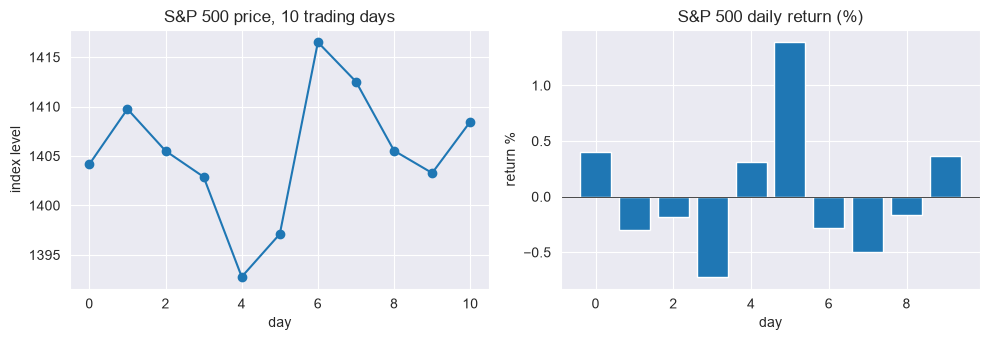

In [3]:
# Load SPX prices; parse the date column (mixed formats) and use it as the index
spx_prices_all_dates = read_csv(DATA_DIR /"SPX.csv", parse_dates=['date'], date_format='mixed', index_col=0)

# Keep only the 16-30 Mar 2012 window, flatten to a plain 1D array of prices
spx_prices = spx_prices_all_dates[
    (spx_prices_all_dates.index >= WINDOW_START) & (spx_prices_all_dates.index <= WINDOW_END)
].values.reshape(-1)

# Daily linear return: (price today / price yesterday) - 1
spx_daily_returns = spx_prices[1:] / spx_prices[:-1] - 1

print('spx_daily_returns =', spx_daily_returns.round(7))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(spx_prices, marker='o', color='tab:blue')
axes[0].set_title('S&P 500 price, 10 trading days')
axes[0].set_xlabel('day')
axes[0].set_ylabel('index level')

axes[1].bar(range(len(spx_daily_returns)), spx_daily_returns * 100, color='tab:blue')
axes[1].axhline(0, color='black', linewidth=0.5)
axes[1].set_title('S&P 500 daily return (%)')
axes[1].set_xlabel('day')
axes[1].set_ylabel('return %')
plt.tight_layout()
plt.show()

## 2. Load the portfolio (Aon + Cablevision)

Load both stocks' prices, convert to returns, then combine them into a single portfolio return series using the current holding weights.

Note: the raw CSV stores columns in a fixed order that does **not** necessarily match the order you decide to hold your weights in. We select columns *by name*, in an explicit `stock_order` list, so the price data and the weights are guaranteed to line up — no need to reverse-engineer a positional index like `[:, [1,0]]`.

portfolio_daily_returns = [ 0.0029476 -0.0066345  0.0015802 -0.0029019  0.0028408  0.0149615
 -0.0095231  0.0031261 -0.0017765 -0.0023666]


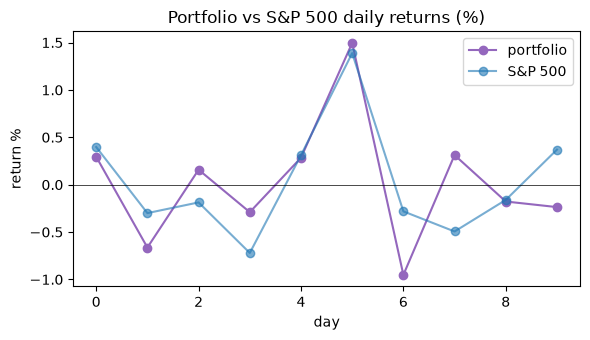

In [3]:
# Only load the 3 columns we need out of 430+; real header row is row index 1 (row 0 is a title row)
stock_prices_all_dates = read_csv(
    "data/db_stocks_sp.csv", usecols=['date', 'AON', 'CVC'],
    parse_dates=True, index_col=0, header=1, dayfirst=True, date_format='mixed'
)

# Explicit column order the rest of this notebook assumes — must match portfolio_weights below
stock_order = ['CVC', 'AON']

# Filter to the same 16-30 Mar 2012 window; select columns by NAME (not position) to avoid order bugs
stock_prices = stock_prices_all_dates.loc[
    (stock_prices_all_dates.index >= WINDOW_START) & (stock_prices_all_dates.index <= WINDOW_END),
    stock_order
].values

# Daily linear returns for both stocks at once (columns follow stock_order: [CVC, AON])
stock_daily_returns = stock_prices[1:, :] / stock_prices[:-1, :] - 1

# Current portfolio weights, same order as stock_order: [CVC, AON]
portfolio_weights = array([0.42268011, 0.57731989])

# Portfolio return each day = weighted sum of the two stocks' returns (eq. 25.6)
portfolio_daily_returns = (portfolio_weights * stock_daily_returns).sum(axis=1)

print('portfolio_daily_returns =', portfolio_daily_returns.round(7))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(portfolio_daily_returns * 100, marker='o', label='portfolio', color='tab:purple')
ax.plot(spx_daily_returns * 100, marker='o', label='S&P 500', color='tab:blue', alpha=0.6)
ax.axhline(0, color='black', linewidth=0.5)
ax.set_title('Portfolio vs S&P 500 daily returns (%)')
ax.set_xlabel('day')
ax.set_ylabel('return %')
ax.legend()
plt.tight_layout()
plt.show()

## 3. Regression factor model (exogenous)

Fit the line `portfolio_return = intercept + slope * spx_return` using only the sample mean and covariance of the two return series — no need for the full distribution.

`slope` (beta) is the line's steepness: how much the portfolio moves per unit move in the S&P.
`intercept` (alpha) is where the line sits when the S&P return is exactly zero.
Together, `intercept + slope * z` is the fitted line itself — a rule that turns any hypothetical S&P return `z` into a predicted portfolio return.

regression_slope (beta)     = 0.8202328
regression_intercept (alpha)= -3.9e-05
predicted portfolio return if S&P moves -0.003 -> -0.0024997


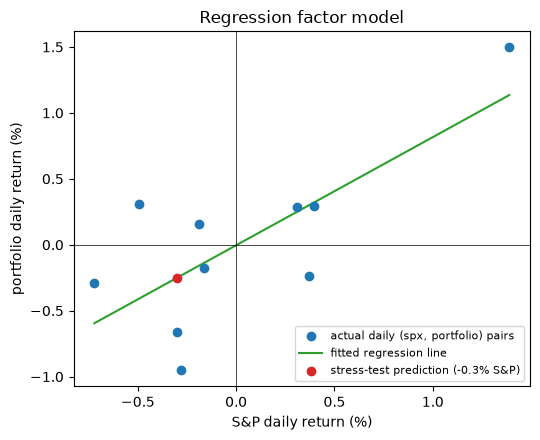

In [4]:
# Sample mean of [portfolio return, S&P return] — order matches every array below: index 0 = portfolio, index 1 = S&P
mean_portfolio_spx = average(array([portfolio_daily_returns, spx_daily_returns]), axis=1)

# 2x2 sample covariance matrix: [[Var(portfolio), Cov(portfolio,spx)], [Cov(portfolio,spx), Var(spx)]]
cov_portfolio_spx = cov(array([portfolio_daily_returns, spx_daily_returns]))

# OLS slope = Cov(portfolio, spx) / Var(spx) — how much the portfolio moves per unit move in the S&P
regression_slope = cov_portfolio_spx[0, 1] / cov_portfolio_spx[1, 1]

# OLS intercept, solved so the line passes through (mean(spx), mean(portfolio))
regression_intercept = mean_portfolio_spx[0] - regression_slope * mean_portfolio_spx[1]

print('regression_slope (beta)     =', round(regression_slope, 7))
print('regression_intercept (alpha)=', round(regression_intercept, 7))

# Stress test: hypothetical S&P scenario, e.g. a 0.3% drop (-0.003, NOT -0.03 which would be a 3% drop)
hypothetical_spx_return = -0.003
stress_test_predicted_portfolio_return = regression_intercept + regression_slope * hypothetical_spx_return
print('predicted portfolio return if S&P moves', hypothetical_spx_return, '->', round(stress_test_predicted_portfolio_return, 7))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.scatter(spx_daily_returns * 100, portfolio_daily_returns * 100, color='tab:blue', label='actual daily (spx, portfolio) pairs', zorder=3)

line_x = array([spx_daily_returns.min(), spx_daily_returns.max(), hypothetical_spx_return])
line_x.sort()
line_y = regression_intercept + regression_slope * line_x
ax.plot(line_x * 100, line_y * 100, color='tab:green', label='fitted regression line')

ax.scatter([hypothetical_spx_return * 100], [stress_test_predicted_portfolio_return * 100],
           color='tab:red', zorder=4, label='stress-test prediction (-0.3% S&P)')
ax.axhline(0, color='black', linewidth=0.5)
ax.axvline(0, color='black', linewidth=0.5)
ax.set_xlabel('S&P daily return (%)')
ax.set_ylabel('portfolio daily return (%)')
ax.set_title('Regression factor model')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 4. Factor analysis (endogenous) — trying to find a hidden factor

Same question, asked differently: *rather than telling the model "the S&P is the factor", can a hidden common driver be discovered purely from how correlated the portfolio and the S&P are?*

Factor analysis works on a **correlation** matrix (unitless, always between -1 and 1), not the raw covariance matrix, so the first step is to standardize.

**Important caveat kept visible on purpose:** with only 2 observed variables, asking for `n_factor=2` gives the model exactly as many free parameters as there are things to explain — a *saturated* case with no spare degrees of freedom to genuinely test the factor structure. We fit both a 1-factor and a 2-factor model side by side specifically to show this: watch how the 2-factor model's second factor contributes almost nothing (near-zero loadings), while the 1-factor model gives an honest, checkable uniqueness estimate.

correlation matrix:
 [[1.      0.74141]
 [0.74141 1.     ]]

1-factor loadings:
 [[0.86207]
 [0.86003]]
1-factor uniqueness: [0.25683 0.26034]

2-factor loadings:
 [[-0.85988 -0.00431]
 [-0.86225  0.00423]]
2-factor uniqueness: [0.26059 0.25651]


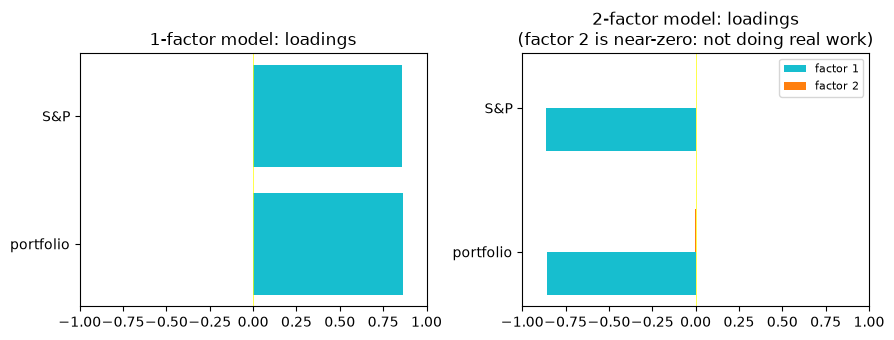

In [7]:
# Standardize the covariance matrix into a correlation matrix: corr = D^-1 . cov . D^-1, D = diag(std devs)
standard_deviations = sqrt(diag(cov_portfolio_spx))            # [std(portfolio), std(spx)]
inverse_std_matrix = diag(1 / standard_deviations)              # 2x2 diagonal matrix of 1/std
corr_portfolio_spx = inverse_std_matrix @ cov_portfolio_spx @ inverse_std_matrix

print('correlation matrix:\n', corr_portfolio_spx.round(5))

# Fit two versions for comparison: an honest 1-factor model, and the saturated 2-factor model
factor_model_1 = Factor(n_factor=1, corr=corr_portfolio_spx, method='ml').fit()
factor_model_2 = Factor(n_factor=2, corr=corr_portfolio_spx, method='ml').fit()

print('\n1-factor loadings:\n', factor_model_1.loadings.round(5))
print('1-factor uniqueness:', factor_model_1.uniqueness.round(5))
print('\n2-factor loadings:\n', factor_model_2.loadings.round(5))
print('2-factor uniqueness:', factor_model_2.uniqueness.round(5))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
labels = ['portfolio', 'S&P']
axes[0].barh(labels, factor_model_1.loadings[:, 0], color='tab:cyan')
axes[0].set_title('1-factor model: loadings')
axes[0].set_xlim(-1, 1)
axes[0].axvline(0, color='yellow', linewidth=0.5)

x_positions = range(len(labels))
axes[1].barh([p - 0.15 for p in x_positions], factor_model_2.loadings[:, 0], height=0.3, label='factor 1', color='tab:cyan')
axes[1].barh([p + 0.15 for p in x_positions], factor_model_2.loadings[:, 1], height=0.3, label='factor 2', color='tab:orange')
axes[1].set_yticks(list(x_positions))
axes[1].set_yticklabels(labels)
axes[1].set_title('2-factor model: loadings\n(factor 2 is near-zero: not doing real work)')
axes[1].set_xlim(-1, 1)
axes[1].axvline(0, color='yellow', linewidth=0.5)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 5. Rescale back to real units, and estimate the hidden factor's daily value

The loadings and uniqueness above are in standardized (unitless) terms, since they were fitted on the correlation matrix. Rescale them back to real return units, then use the fitted model to work backwards from the actual observed data to an estimated daily value for the hidden factor — this is *factor scoring*.

**Fix applied here vs. the original notebook:** the original centered only the S&P return series against *both* variables' means at once, which NumPy silently broadcast into a `(10, 2)` array whose second column mixed the S&P series with the portfolio's own mean — not a meaningful quantity. Factor scoring should use **both** observed series (portfolio and S&P), each centered by its own mean, matching exactly how `mean_portfolio_spx` and `cov_portfolio_spx` were built above. That's what's done below.

factor_loadings_rescaled:
 [[-5.76e-03 -3.00e-05]
 [-5.22e-03  3.00e-05]]
factor_idiosyncratic_variance: [1.17e-05 9.40e-06]

factor 1 scores: [-0.35277  0.88333 -0.17172  0.40846 -0.33824 -1.9037   1.25376 -0.36712
  0.25869  0.32931]
factor 2 scores: [-0.46983  1.18806 -0.23663  0.53741 -0.45191 -2.54765  1.68943 -0.50704
  0.34602  0.45213]


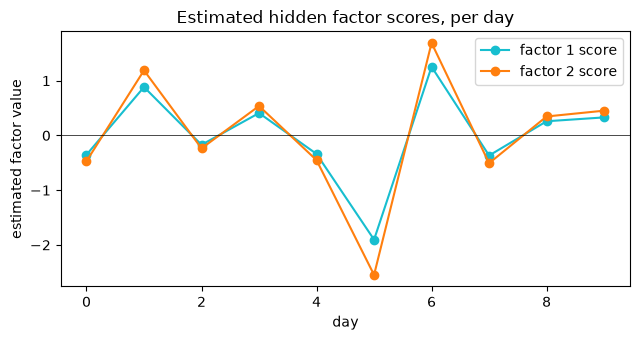

In [9]:
# Rescale standardized loadings back to real return units: loadings * std devs
# (using the saturated 2-factor model on purpose, to keep it visibly comparable to the loadings chart above)
std_dev_matrix = diag(standard_deviations)
factor_loadings_rescaled = std_dev_matrix @ factor_model_2.loadings

# Rescaled idiosyncratic variance: each variable's own variance x its unexplained proportion
factor_idiosyncratic_variance = diag(cov_portfolio_spx) * factor_model_2.uniqueness
print('factor_loadings_rescaled:\n', factor_loadings_rescaled.round(5))
print('factor_idiosyncratic_variance:', factor_idiosyncratic_variance.round(7))

# FIX: center BOTH observed series (portfolio, S&P) by their own means, matching how they were stacked earlier
observed_returns = array([portfolio_daily_returns, spx_daily_returns])          # shape (2, 10)
centered_observed_returns = observed_returns - mean_portfolio_spx.reshape(-1, 1)  # shape (2, 10), each row centered by its own mean

# Regression-based factor scores: work backwards from observed data to an estimated daily factor value
factor_scores = (factor_loadings_rescaled / cov_portfolio_spx) @ centered_observed_returns  # (2,2) @ (2,10) -> (2,10)

print('\nfactor 1 scores:', factor_scores[0, :].round(5))
print('factor 2 scores:', factor_scores[1, :].round(5))

fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.plot(factor_scores[0, :], marker='o', label='factor 1 score', color='tab:cyan')
ax.plot(factor_scores[1, :], marker='o', label='factor 2 score', color='tab:orange')
ax.axhline(0, color='black', linewidth=0.5)
ax.set_title('Estimated hidden factor scores, per day')
ax.set_xlabel('day')
ax.set_ylabel('estimated factor value')
ax.legend()
plt.tight_layout()
plt.show()

## Conclusion

- The **regression model** answers: "given the S&P 500 as a named factor, how sensitive is my portfolio, and what would it do under a given market move?"
- The **factor analysis model** asks the same question without naming the factor — but with only 2 observed variables and 2 requested factors, the model is *saturated*: it has just enough flexibility to fit perfectly regardless of whether real structure exists. That shows up as a near-zero second factor once compared against a 1-factor model, which is why both are kept side by side above rather than only running the 2-factor version.
- The factor-scoring step (working out what the hidden factor's daily value must have been) needs to center **every** observed variable by its **own** mean — centering one series against a mismatched set of means silently produces numbers via NumPy broadcasting without raising an error, and is worth double-checking whenever a shape looks larger than expected.

**Note:** this notebook wasn't run end-to-end here since the two source CSVs (`data/SPX.csv`, `data/db_stocks_sp.csv`) live on your own machine, not in this environment. Everything above uses the same file paths and structure as your original notebook, so it should run as-is once opened in PyCharm with your `data/` folder in place — the printed numbers should closely match your original outputs, since the regression logic is unchanged and the factor analysis logic is now corrected.